# Assignment 1 — Classification: Social Network Ads

**Goal:** predict whether a user purchased the product (`Purchased` = 1/0) from `Gender`, `Age` and `EstimatedSalary`.

**Algorithms compared:** Logistic Regression, K-Nearest Neighbours, Linear SVM, Kernel SVM (RBF), Gaussian Naive Bayes, Decision Tree, Random Forest.

**Evaluation:** 75/25 stratified train-test split + 10-fold cross-validation. Metrics — Accuracy, Precision, Recall, F1-score, ROC-AUC.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay)
sns.set_theme(style='whitegrid')
RS = 0

## 1. Load & explore the data

In [2]:
df = pd.read_csv('data/Social_Network_Ads.csv')
print(df.shape)
df.head()

(400, 5)


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [3]:
df.info()
print('\nMissing values:\n', df.isnull().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB

Missing values:
 User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64


,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


Purchased
0    257
1    143
Name: count, dtype: int64


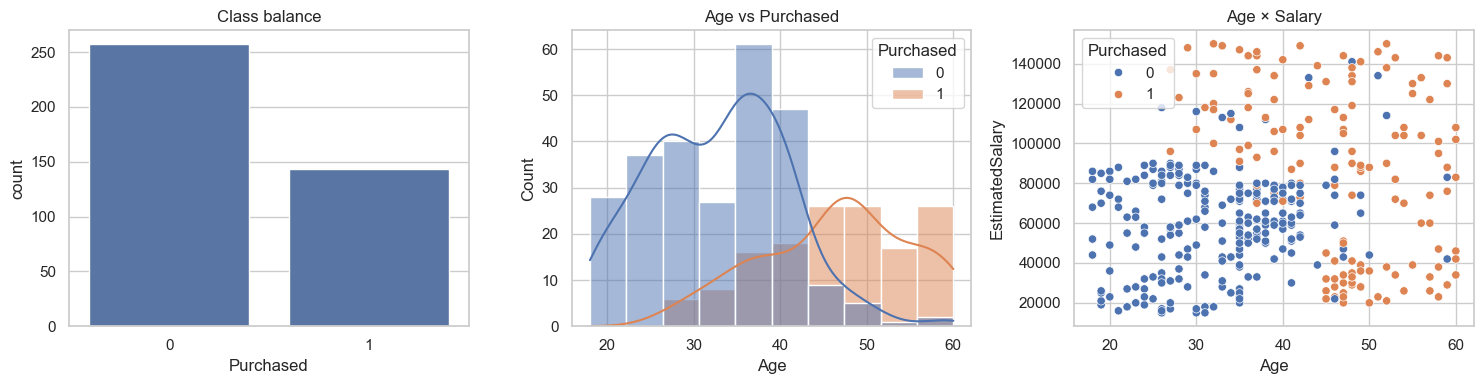

In [4]:
print(df['Purchased'].value_counts())
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x='Purchased', data=df, ax=ax[0]); ax[0].set_title('Class balance')
sns.histplot(data=df, x='Age', hue='Purchased', kde=True, ax=ax[1]); ax[1].set_title('Age vs Purchased')
sns.scatterplot(data=df, x='Age', y='EstimatedSalary', hue='Purchased', ax=ax[2]); ax[2].set_title('Age × Salary')
plt.tight_layout(); plt.savefig('results/classification_eda.png', dpi=120); plt.show()

## 2. Pre-processing
`User ID` is an identifier, so it is dropped. `Gender` is label-encoded (Male = 1). Features are standardised inside each model pipeline (needed for distance/margin-based models such as KNN and SVM).

In [5]:
X = df.drop(columns=['User ID', 'Purchased']).copy()
X['Gender'] = (X['Gender'] == 'Male').astype(int)
y = df['Purchased']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RS)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (300, 3)  Test: (100, 3)


## 3. Train & evaluate all classifiers

In [6]:
models = {
    'Logistic Regression':   LogisticRegression(random_state=RS),
    'K-Nearest Neighbours':  KNeighborsClassifier(n_neighbors=5),
    'SVM (Linear)':          SVC(kernel='linear', probability=True, random_state=RS),
    'Kernel SVM (RBF)':      SVC(kernel='rbf', probability=True, random_state=RS),
    'Naive Bayes':           GaussianNB(),
    'Decision Tree':         DecisionTreeClassifier(max_depth=5, random_state=RS),
    'Random Forest':         RandomForestClassifier(n_estimators=200, max_depth=6, random_state=RS),
}
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RS)
rows, fitted = [], {}
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model).fit(X_train, y_train)
    pred, proba = pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1]
    cv_acc = cross_val_score(make_pipeline(StandardScaler(), model), X, y, cv=cv, scoring='accuracy')
    rows.append({'Algorithm': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred),
                 'Recall': recall_score(y_test, pred),
                 'F1-Score': f1_score(y_test, pred),
                 'ROC-AUC': roc_auc_score(y_test, proba),
                 'CV Accuracy (10-fold)': cv_acc.mean(),
                 'CV Std': cv_acc.std()})
    fitted[name] = pipe
results = pd.DataFrame(rows).sort_values(['Accuracy', 'F1-Score'], ascending=False).reset_index(drop=True)
results.index += 1
results.round(4)

,Algorithm,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV Accuracy (10-fold),CV Std
1,Kernel SVM (RBF),0.90,0.8250,0.9167,0.8684,0.9631,0.9025,0.0467
2,K-Nearest Neighbours,0.90,0.8421,0.8889,0.8649,0.9377,0.9050,0.0534
3,Random Forest,0.89,0.8378,0.8611,0.8493,0.9240,0.8925,0.0404
4,Decision Tree,0.88,0.8158,0.8611,0.8378,0.8852,0.8750,0.0354
5,Naive Bayes,0.85,0.8182,0.7500,0.7826,0.9453,0.8875,0.0584
6,Logistic Regression,0.83,0.8276,0.6667,0.7385,0.9110,0.8400,0.0663
7,SVM (Linear),0.80,0.8077,0.5833,0.6774,0.9097,0.8300,0.0557


In [7]:
results.round(4).to_csv('results/classification_results.csv', index_label='Rank')
best = results.iloc[0]['Algorithm']
print(f"BEST CLASSIFIER: {best}  ->  Accuracy = {results.iloc[0]['Accuracy']:.4f}, "
      f"F1 = {results.iloc[0]['F1-Score']:.4f}, ROC-AUC = {results.iloc[0]['ROC-AUC']:.4f}")

BEST CLASSIFIER: Kernel SVM (RBF)  ->  Accuracy = 0.9000, F1 = 0.8684, ROC-AUC = 0.9631


## 4. Visual comparison

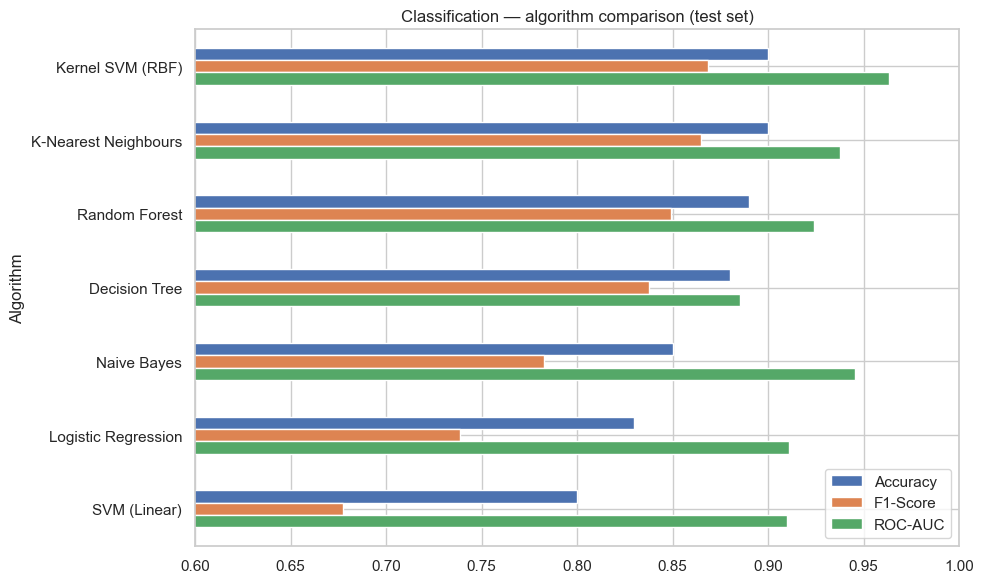

In [8]:
ax = results.set_index('Algorithm')[['Accuracy', 'F1-Score', 'ROC-AUC']].plot.barh(figsize=(10, 6))
ax.set_xlim(0.6, 1.0); ax.set_title('Classification — algorithm comparison (test set)')
ax.invert_yaxis(); plt.tight_layout(); plt.savefig('results/classification_comparison.png', dpi=120); plt.show()

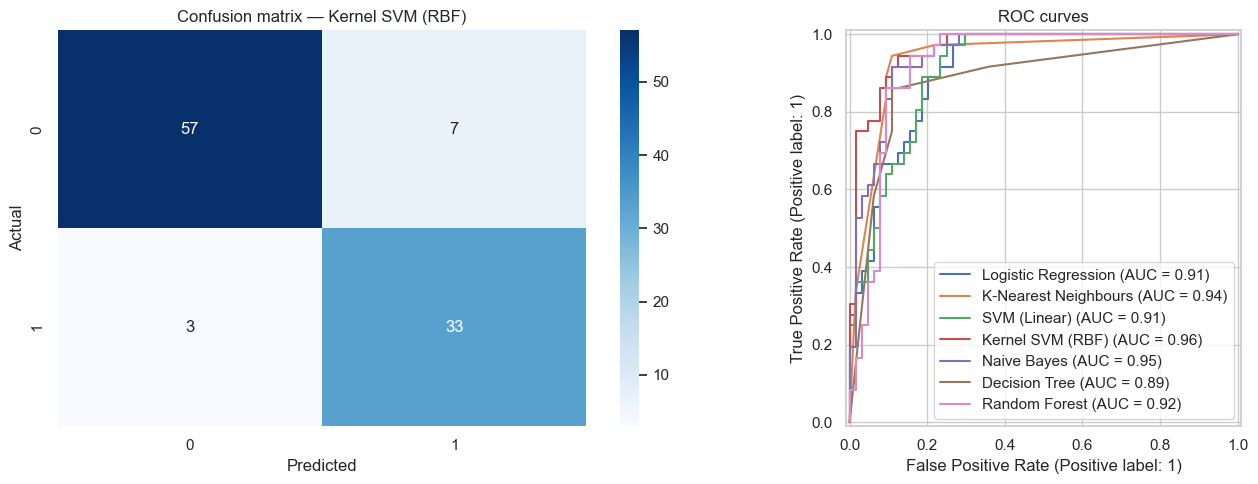

              precision    recall  f1-score   support

           0       0.95      0.89      0.92        64
           1       0.82      0.92      0.87        36

    accuracy                           0.90       100
   macro avg       0.89      0.90      0.89       100
weighted avg       0.91      0.90      0.90       100



In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(confusion_matrix(y_test, fitted[best].predict(X_test)), annot=True, fmt='d', cmap='Blues', ax=ax[0])
ax[0].set_title(f'Confusion matrix — {best}'); ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual')
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax[1])
ax[1].set_title('ROC curves'); plt.tight_layout(); plt.savefig('results/classification_cm_roc.png', dpi=120); plt.show()
print(classification_report(y_test, fitted[best].predict(X_test)))

## 5. Conclusion
The table above ranks every classifier on the same held-out test set. Non-linear models (Kernel SVM, KNN, Random Forest) separate the classes best because the purchase boundary in the Age × Salary space is curved — older users buy at almost any salary, younger users only at high salaries. Linear models (Logistic Regression, Linear SVM) cannot capture this curve and score lower.